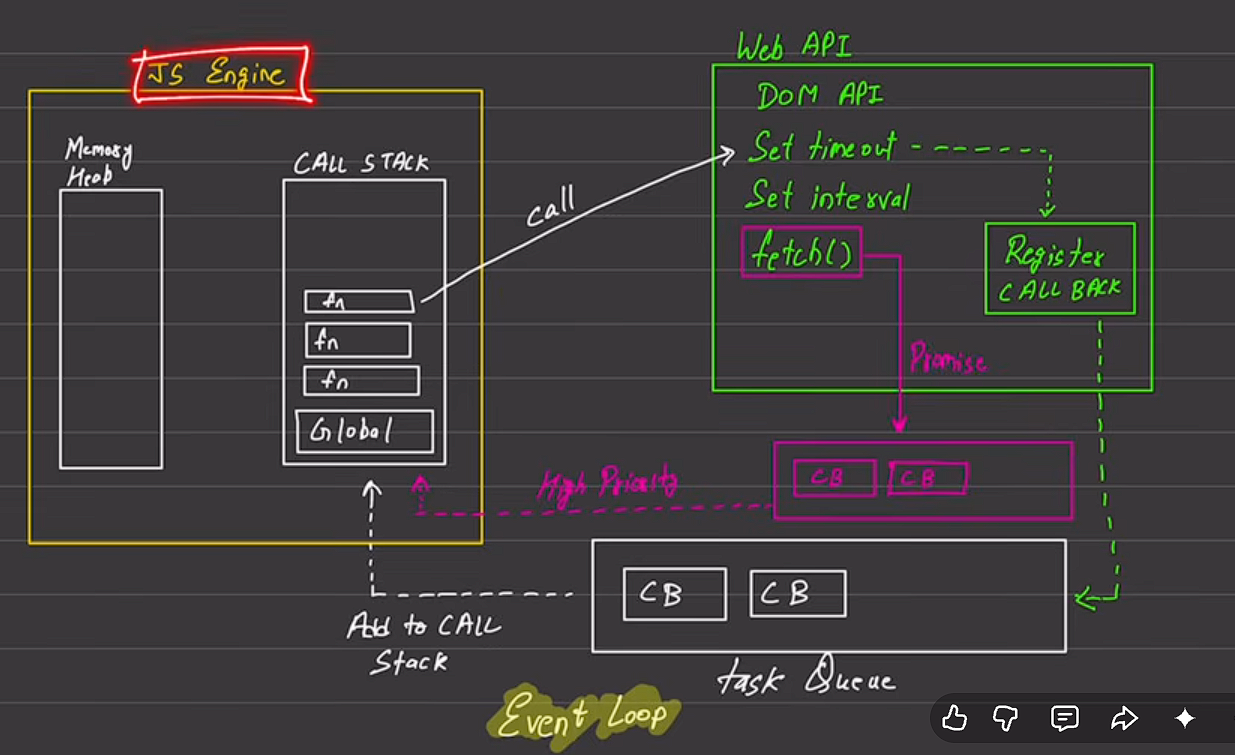


# JavaScript Runtime, Execution Model & The Event Loop

```
+---------------------------------------------------------------------------------------------------+
|                                     JAVASCRIPT RUNTIME ENVIRONMENT                                |
|                                                                                                   |
|   +-------------------------- JS ENGINE --------------------------+       +------ WEB APIS -----+  |
|   |                                                               |       | - DOM API           |  |
|   |   +--- MEMORY HEAP ---+       +--------- CALL STACK --------+ | call  | - setTimeout()      |  |
|   |   |                   |       |                             | |------>| - setInterval()     |  |
|   |   |  Objects,         |       |   [ fn()                  ] | |       | - fetch()           |  |
|   |   |  Variables,       |       |   [ fn()                  ] | |       +----------+----------+  |
|   |   |  Data Allocation  |       |   [ Global Exec Context   ] | |                  |                 |
|   |   +-------------------+       +--------------+--------------+ |                  | Promise         |
|   |                                              ^                |                  v                 |
|   +----------------------------------------------|----------------+    +-----------------------------+ |
|                                                  |                     |  MICROTASK QUEUE (High Prio)| |
|                                                  |                     |  [ CB (Promise) ] [ CB ]    | |
|                                            Event |                     +--------------+--------------+ |
|                                             Loop | (Pushes to Stack)                  |                 |
|                                                  |                                    | Register CB     |
|                                                  |                                    v                 |
|                                                  |                     +-----------------------------+ |
|                                                  +---------------------+  TASK QUEUE / CALLBACK QUEUE| |
|                                                                        |  [ CB (Timer) ] [ CB ]      | |
|                                                                        +-----------------------------+ |
+---------------------------------------------------------------------------------------------------+
```

---

## 1. JavaScript Basics: Single-Threaded & Synchronous

By default, JavaScript is:
* **Single-Threaded:** It contains only one **Call Stack** and executes one instruction at a time[cite: 1].
* **Synchronous:** Code runs strictly line by line in sequence[cite: 1]. Each statement waits for the preceding statement to finish before executing[cite: 1].

### Execution Context Components
* **Memory Heap:** Allocates and stores memory dynamically for variables, objects, and function definitions[cite: 1, 3].
* **Call Stack:** Operates as a LIFO (Last In, First Out) data structure that tracks active function execution contexts[cite: 1, 3].

```javascript
console.log(1); // Executes first
console.log(2); // Waits for console.log(1) to finish
```

---

## 2. Blocking vs. Non-Blocking Code

| Feature | Blocking Code | Non-Blocking Code |
| :--- | :--- | :--- |
| **Execution Flow** | Halts program flow until the current task finishes[cite: 2]. | Does not halt execution; processes background work separately[cite: 2]. |
| **Typical Example** | `fs.readFileSync("file.txt")`[cite: 2] | `fs.readFile("file.txt", callback)`[cite: 2] |
| **Browser Impact** | Freezes UI interactions, inputs, and animations. | Keeps the UI responsive while awaiting data. |

---

## 3. Asynchronous Architecture & The Event Loop

Because the JS Engine only has a single call stack[cite: 1], asynchronous workflows are delegated to the surrounding **Runtime Environment** (Browser or Node.js)[cite: 3].

### Architectural Components
1. **Call Stack:** Executes synchronous JavaScript code[cite: 1, 3].
2. **Web APIs:** Browser threads providing helper APIs:
   * DOM manipulation (`document.querySelector`, click listeners)[cite: 3].
   * Timers (`setTimeout`, `setInterval`)[cite: 3].
   * Network requests (`fetch()`, `XMLHttpRequest`)[cite: 3].
3. **Microtask Queue (High Priority):** Holds callbacks from resolved **Promises** (`.then()`, `catch()`, `finally()`) and `queueMicrotask`[cite: 3].
4. **Task Queue / Callback Queue:** Holds regular callbacks from timer completions (`setTimeout`, `setInterval`) and user events[cite: 3].
5. **Event Loop:** Continuously monitors the Call Stack[cite: 3]. When the Call Stack is completely empty